In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
real = pd.read_csv("True.csv")
fake = pd.read_csv("Fake.csv")

In [3]:
real_text = real["text"].head(2000).fillna("")
fake_text = fake["text"].head(2000).fillna("")

In [4]:
# count excessive punctuation
real_exclaim = real_text.str.count(r'!').sum()
fake_exclaim = fake_text.str.count(r'!').sum()

In [5]:
real_question = real_text.str.count(r'\?').sum()
fake_question = fake_text.str.count(r'\?').sum()

In [6]:
# count words written in capital letters
real_caps = real_text.str.findall(r'\b[A-Z]{2,}\b').str.len().sum()
fake_caps = fake_text.str.findall(r'\b[A-Z]{2,}\b').str.len().sum()

In [7]:
# 3. Count sensational words
sensational = r'\b(shocking|unbelievable|urgent|breaking|outrageous|horrifying|exposed|secret)\b'

real_sensational = real_text.str.lower().str.count(sensational).sum()
fake_sensational = fake_text.str.lower().str.count(sensational).sum()

In [8]:
# Calculate total words
real_words = real_text.str.findall(r'\b\w+\b').str.len().sum()
fake_words = fake_text.str.findall(r'\b\w+\b').str.len().sum()


In [9]:
# Compare features per 1,000 words
result = pd.DataFrame({
    "Feature": [
        "Exclamation Marks (!)",
        "Question Marks (?)",
        "Capitalized Words",
        "Sensational Words"
    ],
    "Real News": [
        real_exclaim / max(real_words, 1) * 1000,
        real_question / max(real_words, 1) * 1000,
        real_caps / max(real_words, 1) * 1000,
        real_sensational / max(real_words, 1) * 1000
    ],
    "Fake News": [
        fake_exclaim / max(fake_words, 1) * 1000,
        fake_question / max(fake_words, 1) * 1000,
        fake_caps / max(fake_words, 1) * 1000,
        fake_sensational / max(fake_words, 1) * 1000
    ]
})

result[["Real News", "Fake News"]] = result[
    ["Real News", "Fake News"]
].round(2)

print(result)

                 Feature  Real News  Fake News
0  Exclamation Marks (!)       0.40       1.77
1     Question Marks (?)       0.29       3.27
2      Capitalized Words       9.50       8.21
3      Sensational Words       0.18       0.39


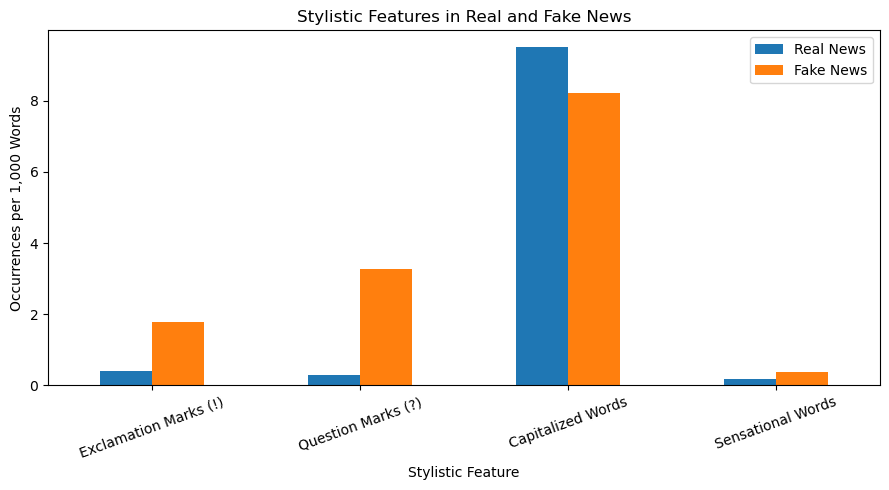

In [10]:
# Visualize the comparison
result.plot(x="Feature",y=["Real News", "Fake News"],kind="bar",figsize=(9, 5))

plt.title("Stylistic Features in Real and Fake News")
plt.ylabel("Occurrences per 1,000 Words")
plt.xlabel("Stylistic Feature")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()
